Contagem de alunos por curso:
Curso
Banco de Dados    10
Design            15
Java              15
Python            20
dtype: int64


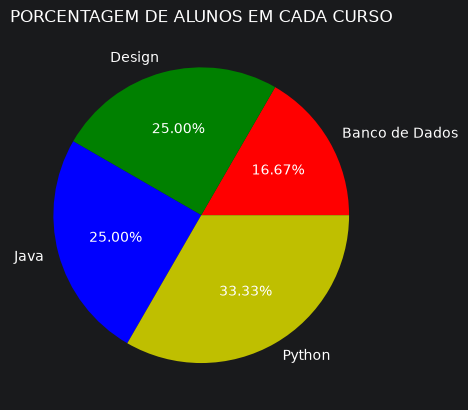

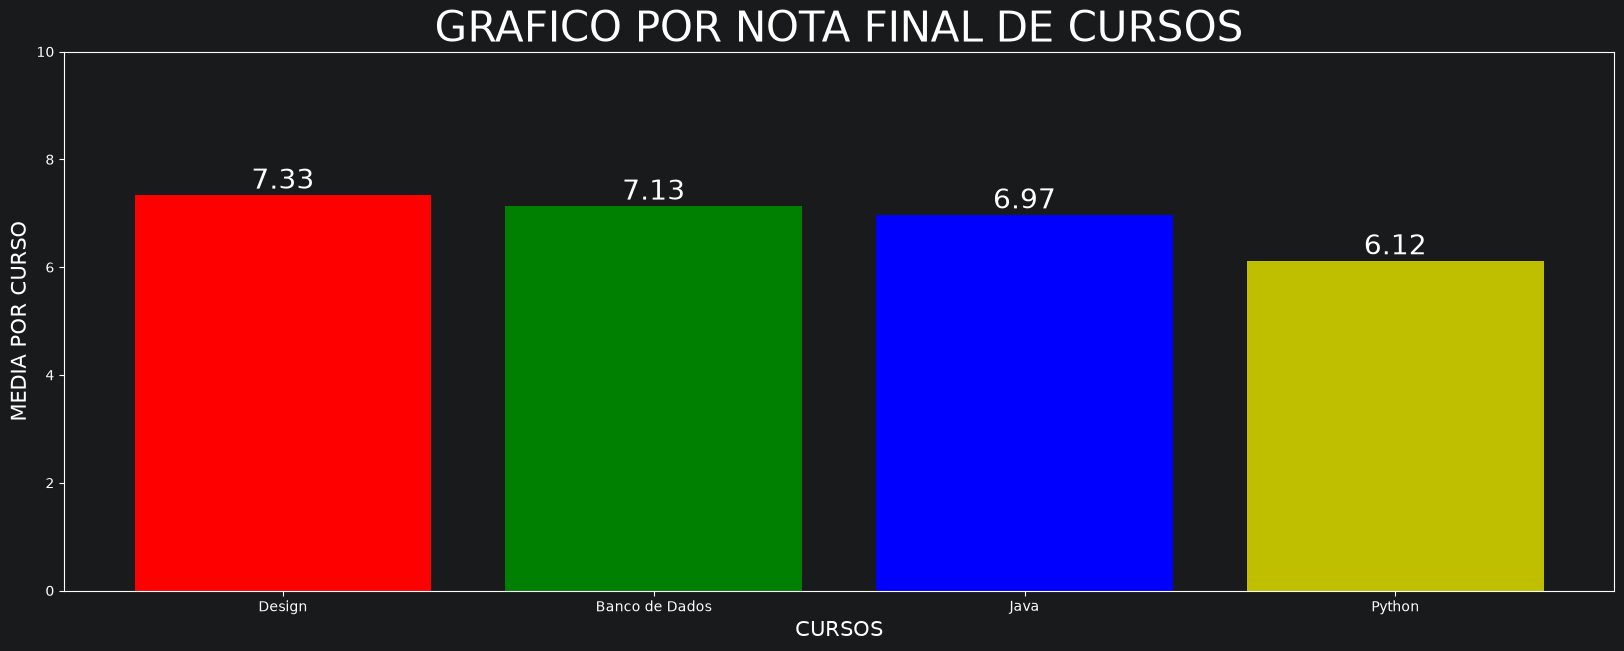

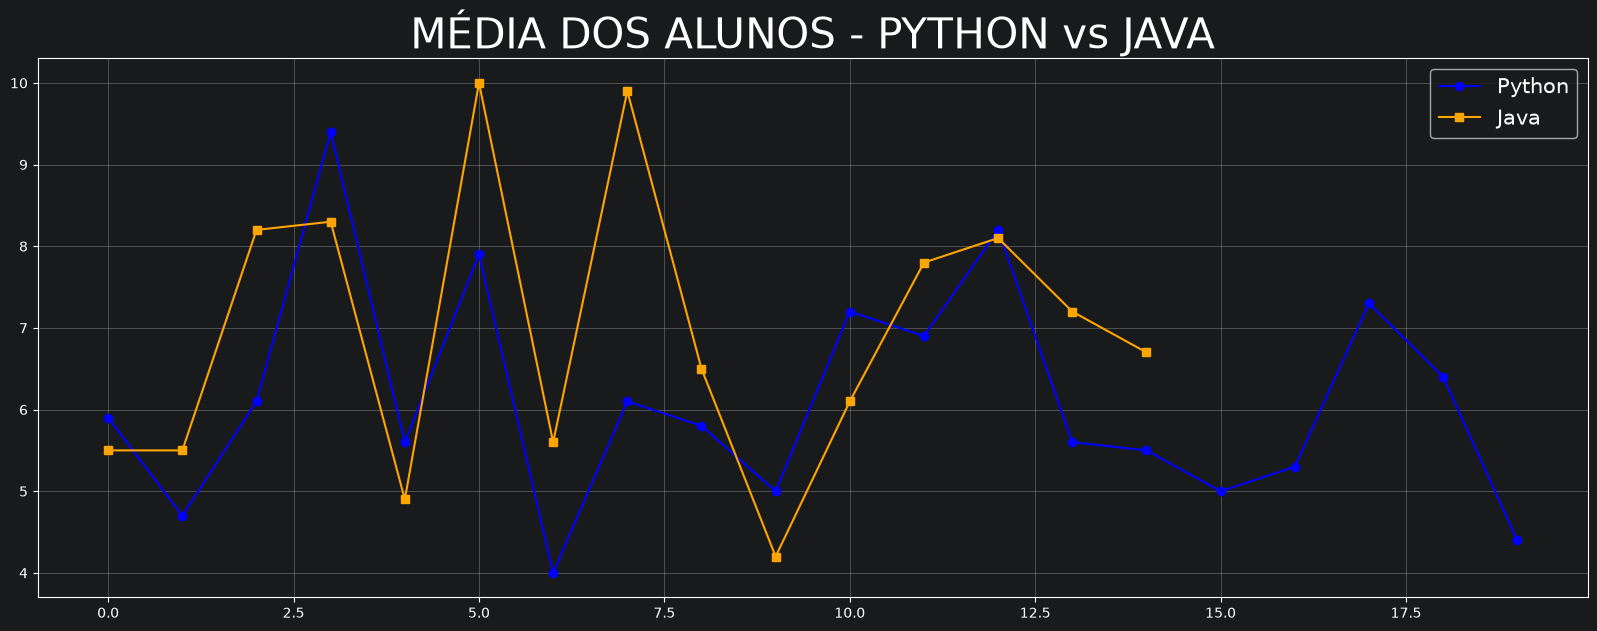

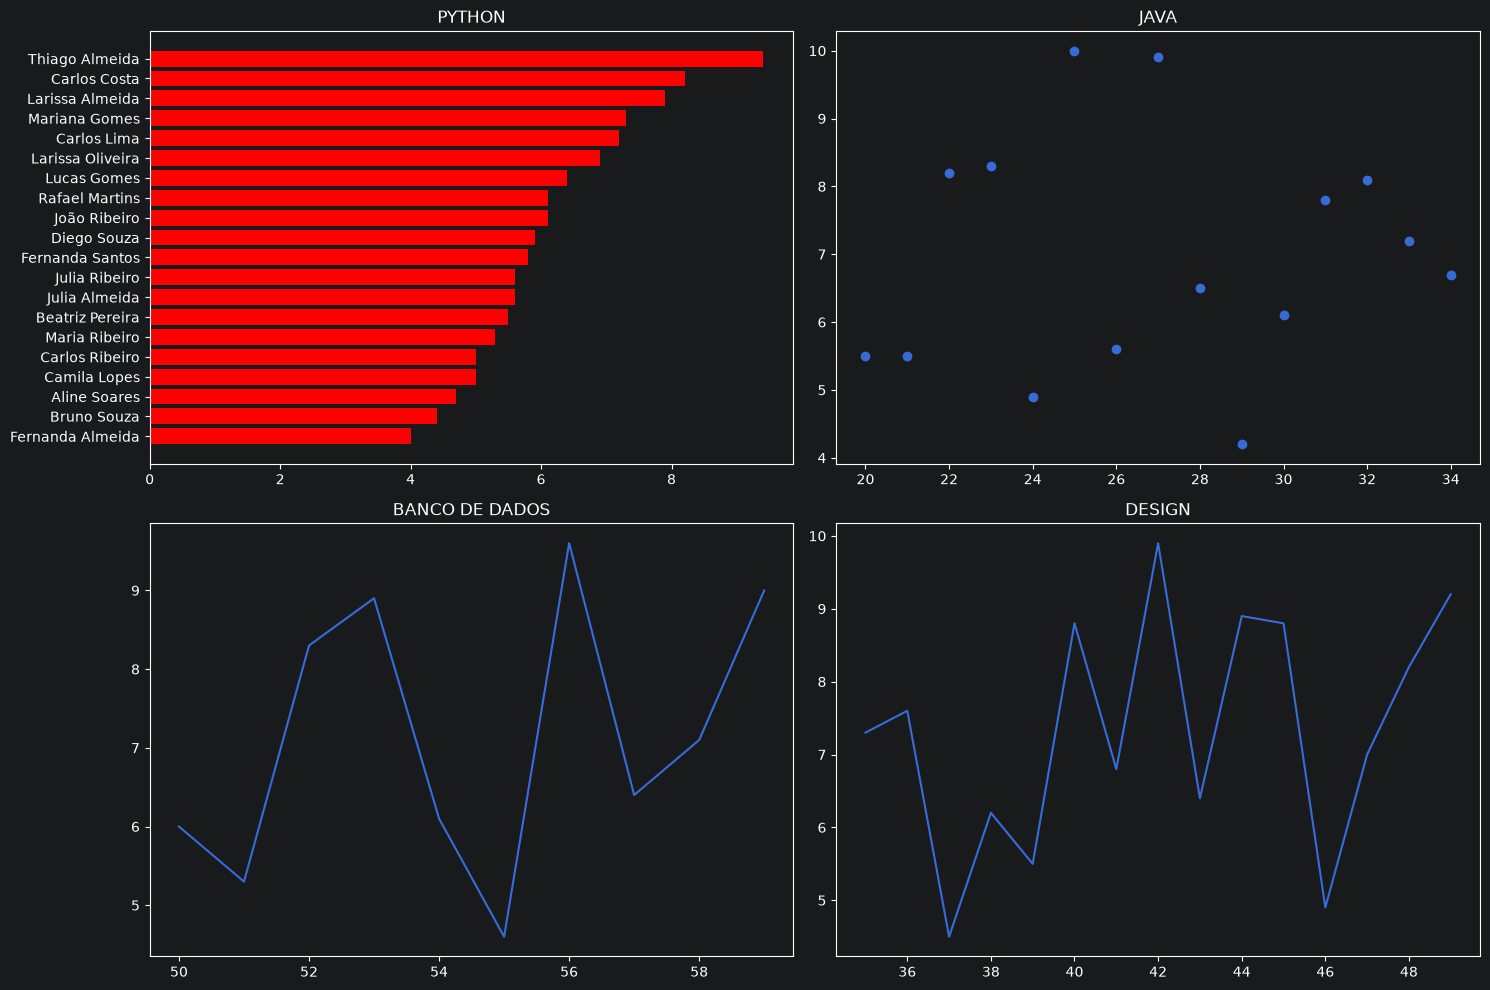

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Carregando a base de dados
df_alunos = pd.read_csv("alunos_senai_sig.csv")

# =========================================================================
# # GRAFICO EM PIZZA - porcentagem de alunos em cada turma
# =========================================================================

contagem_de_cursos = df_alunos.groupby('Curso').size()
print("Contagem de alunos por curso:")
print(contagem_de_cursos)

plt.figure()
pizza = plt.pie(
    contagem_de_cursos.values,
    labels=contagem_de_cursos.index,
    autopct='%1.2f%%',
    colors=['r', 'g', 'b', 'y'],
)

plt.title("PORCENTAGEM DE ALUNOS EM CADA CURSO")
plt.show()

# =========================================================================
# # GRAFICO DE MÉDIA DE CADA TURMA
# =========================================================================

plt.figure(figsize=(20, 7))

media_por_curso = df_alunos.groupby('Curso')["Media_Final"].mean().sort_values(ascending=False)

barra = plt.bar(
    media_por_curso.index,
    media_por_curso.values,
    color=['r', 'g', 'b', 'y'],
)

plt.title("GRAFICO POR NOTA FINAL DE CURSOS", fontsize=30)
plt.ylabel("MEDIA POR CURSO", fontsize=15)
plt.xlabel("CURSOS", fontsize=15)
plt.ylim(0, 10)

# Colocando os valores numéricos em cima de cada barra
for coluna in barra:
    yvalor = coluna.get_height()
    plt.text(
        coluna.get_x() + coluna.get_width() / 2,
        yvalor,
        f'{yvalor:.2f}',
        fontsize=20,
        ha='center',
        va='bottom',
    )

plt.show()

# =========================================================================
# # MEDIA DE NOTAS INDIVIDUAL POR ALUNOS DO CURSO
# =========================================================================

notas_python = df_alunos[df_alunos["Curso"] == "Python"].reset_index(drop=True)
notas_java = df_alunos[df_alunos["Curso"] == "Java"].reset_index(drop=True)

plt.figure(figsize=(20, 7))

# Plotando as duas linhas separadas para evitar misturar os eixos
plt.plot(notas_python.index, notas_python["Media_Final"], label="Python", color="blue", marker="o")
plt.plot(notas_java.index, notas_java["Media_Final"], label="Java", color="orange", marker="s")

plt.grid(True)
plt.title("MÉDIA DOS ALUNOS - PYTHON vs JAVA", fontsize=30)
plt.legend(fontsize=15)
plt.savefig("media_final_alunos_curso_python.png")
plt.show()

# =========================================================================
# # LIDANDO COM SUBPLOTS
# =========================================================================

fig, axs = plt.subplots(2, 2, figsize=(15, 10))

df_python = df_alunos[df_alunos["Curso"] == "Python"].sort_values(by="Media_Final")
df_java = df_alunos[df_alunos["Curso"] == "Java"]
df_banco_de_dados = df_alunos[df_alunos["Curso"] == "Banco de Dados"]
df_design = df_alunos[df_alunos["Curso"] == "Design"]

# Subplot [0,0] - Python
axs[0, 0].barh(
    df_python['Nome'],
    df_python["Media_Final"],
    color='r',
)
axs[0, 0].set_title("PYTHON")

# Subplot [0,1] - Java
axs[0, 1].scatter(df_java.index, df_java["Media_Final"])
axs[0, 1].set_title("JAVA")

# Subplot [1,0] - Banco de Dados
axs[1, 0].plot(df_banco_de_dados.index, df_banco_de_dados["Media_Final"])
axs[1, 0].set_title("BANCO DE DADOS")

# Subplot [1,1] - Design
axs[1, 1].plot(df_design.index, df_design["Media_Final"])
axs[1, 1].set_title("DESIGN")

plt.tight_layout()
fig.savefig("media_final_alunos_cursos.png")
plt.show()
